# Data representation — figures of the systematic review

Generates the data figures of *Deep Learning Approaches for Drought Forecasting, Monitoring and Impact Assessment: A Comprehensive Systematic Review*, in the order they appear in the paper, from `data/data_extraction.xlsx`. Each figure is saved as `figures/FigureN.pdf`.

| Figure | Content | Source sheet |
|---|---|---|
| 1–2 | Review workflow and extraction scheme (LaTeX/TikZ diagrams, not generated here) | — |
| 3 | Publications per year and cumulative share | `Sheet1` |
| 4 | Citations per publication year | `Sheet1` |
| 5 | Journals with the most publications | `Sheet1` |
| 6 | Word cloud of study titles | `Sheet1` |
| 7 | Number of studies per country | `Sheet2` |
| 8 | Drought types in the five most studied countries | `Sheet2` |
| 9 | DL architecture families per year | `Sheet3` + `Sheet1` |
| 10 | Generic and specific DL models | `Sheet3` |
| 11 | Remote sensing data sources by category | `Sheet2` |
| 12 | Drought indices per DL architecture | `Sheet3` + `Sheet2` |
| 13 | Task types per DL architecture | `Sheet3` + `Sheet2` |
| 14 | Minimum and maximum lead times | `Sheet4` |

**Requirements:** `pandas`, `openpyxl`, `numpy`, `matplotlib`, `seaborn`, `wordcloud`, `geopandas`.
Figure 7 uses the Natural Earth *Admin 0 – Countries* shapefile (1:10m, https://www.naturalearthdata.com/downloads/10m-cultural-vectors/), read directly from `notebooks/ne_10m_admin_0_countries.zip`; another copy can be given with the `NE_COUNTRIES_SHP` environment variable.

## Setup

In [1]:
import os
import re
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter
from wordcloud import WordCloud

warnings.filterwarnings("ignore", category=UserWarning, module="matplotlib")
warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")
np.random.seed(42)

# Paths (the notebook can be run from the repository root or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "data_extraction.xlsx"
FIG_DIR = ROOT / "figures"
SHAPEFILE = Path(os.environ.get("NE_COUNTRIES_SHP", ROOT / "notebooks" / "ne_10m_admin_0_countries.zip"))
FIG_DIR.mkdir(exist_ok=True)

# Spreadsheet: Sheet1 bibliographic data, Sheet2 research scope and input data,
# Sheet3 modeling approach, Sheet4 lead times
sheets = pd.read_excel(DATA, sheet_name=None)
biblio, scope, models, lead = (sheets[s] for s in ("Sheet1", "Sheet2", "Sheet3", "Sheet4"))
scope.columns = scope.columns.str.strip()  # e.g. "Task_Type " -> "Task_Type"

# Style shared by all figures: Arial, YlOrBr palette, no titles, white style
TXT = "black"
mpl.rcParams.update({"font.family": "Arial", "font.size": 13, "pdf.fonttype": 42, "ps.fonttype": 42,
                     "figure.dpi": 72, "savefig.dpi": 300})
sns.set_theme(context="paper", style="white", palette="YlOrBr", rc={"font.family": "Arial", "font.size": 13})
SMALL = {"axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10}
LARGE = {"axes.labelsize": 13, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12}


def savefig(fig, number):
    """Save a figure as figures/Figure<number>.pdf (300 dpi, transparent background)."""
    path = FIG_DIR / f"Figure{number}.pdf"
    fig.savefig(path, dpi=300, bbox_inches="tight", pad_inches=0.1, transparent=True)
    plt.show()
    plt.close(fig)
    print("saved", path.relative_to(ROOT).as_posix())


def explode(df, column, sep=";"):
    """One row per ';'-separated entry of `column` (empty and N/I entries removed)."""
    out = df.dropna(subset=[column]).copy()
    out[column] = out[column].astype(str).str.split(sep)
    out = out.explode(column, ignore_index=True)
    out[column] = out[column].str.strip()
    return out[~out[column].isin(["", "N/I"])].reset_index(drop=True)


def gray_spines(ax, color="gray", width=1.0):
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor(color)
        spine.set_linewidth(width)

## Figure 3 — Temporal distribution of the publications
Number of selected studies per year (2015–2025) and cumulative share of the total.

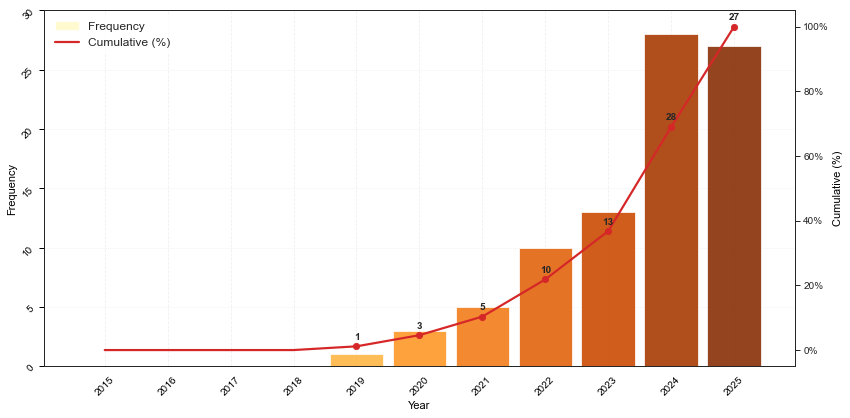

saved figures/Figure3.pdf


In [2]:
years = pd.to_numeric(biblio["Year"], errors="coerce").dropna().astype(int)
per_year = years[(years >= 2015) & (years <= 2025)].value_counts().reindex(range(2015, 2026), fill_value=0)
cum_pct = per_year.cumsum() / per_year.sum() * 100

with plt.rc_context(SMALL):
    fig, ax1 = plt.subplots(figsize=(12, 6))
    ax1.bar(per_year.index, per_year.values, color=sns.color_palette("YlOrBr", len(per_year)), alpha=0.9,
            label="Frequency", width=0.85, edgecolor="white", linewidth=0.8)
    ax1.set_xlabel("Year", color=TXT)
    ax1.set_ylabel("Frequency", color=TXT)
    ax1.tick_params(axis="both", colors=TXT, labelrotation=45)
    ax1.set_xticks(per_year.index)
    ax1.grid(True, axis="y", linestyle=":", linewidth=0.8, alpha=0.4)
    ax1.grid(True, axis="x", linestyle="--", alpha=0.3)
    y_max = max(5, int(np.ceil(per_year.max() / 5) * 5))
    ax1.set_ylim(0, y_max)
    ax1.set_yticks(np.arange(0, y_max + 1, 5))

    ax2 = ax1.twinx()
    ax2.plot(per_year.index, cum_pct.values, color="#D62728", linewidth=2.2, label="Cumulative (%)")
    nonzero = per_year > 0
    ax2.scatter(per_year.index[nonzero], cum_pct[nonzero], color="#D62728", s=40, zorder=5)
    ax2.set_ylabel("Cumulative (%)", color=TXT)
    ax2.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    for x, y, n in zip(per_year.index, cum_pct.values, per_year.values):  # number of studies above each point
        if n > 0:
            ax2.text(x, y + 1.5, f"{n}", ha="center", va="bottom", fontsize=10, fontweight="bold", zorder=6)

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left", facecolor="white", framealpha=0.75, edgecolor="none",
               prop={"family": "Arial", "size": 12})
    for spine in ax1.spines.values():
        spine.set_linewidth(0.8)
        spine.set_edgecolor("#999999")
    fig.tight_layout()
    savefig(fig, 3)

## Figure 4 — Citations per publication year
Distribution of the number of citations of the selected studies, grouped by publication year.

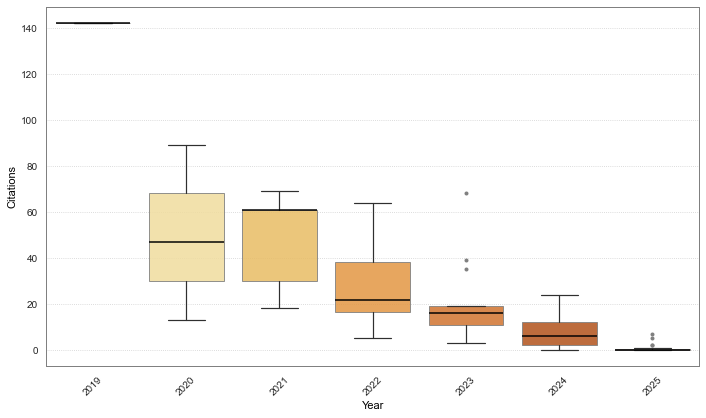

saved figures/Figure4.pdf


In [3]:
cit = biblio.dropna(subset=["Year", "Citations"]).astype({"Year": int})
order = sorted(cit["Year"].unique())

with plt.rc_context(SMALL):
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.boxplot(x="Year", y="Citations", data=cit, order=order, ax=ax,
                palette=sns.color_palette("YlOrBr", len(order)), boxprops=dict(alpha=0.85),
                medianprops=dict(color="black", linewidth=1.5),
                flierprops=dict(marker="o", markersize=4, markerfacecolor="gray", markeredgewidth=0))
    ax.set_xlabel("Year", color=TXT)
    ax.set_ylabel("Citations", color=TXT)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.4)
    for patch in ax.patches:
        patch.set_edgecolor("gray")
        patch.set_linewidth(1)
    gray_spines(ax)
    fig.tight_layout()
    savefig(fig, 4)

## Figure 5 — Journals with the most publications
Journals with at least three selected studies; the remaining journals are grouped as *Others (<3)*. Percentages refer to the plotted total.

,Frequency
Journal,
Remote Sensing,12
Int. J. Appl. Earth Obs. & Geoinfo.,5
Remote Sens. Environ.,5
J. Hydrol.,4
Earth Sci. Informatics,3
Remote Sens. Appl.: Soc. & Environ.,3
IEEE J. Sel. Top. Appl. Earth Obs. Remote Sens.,3
Others (<3),52


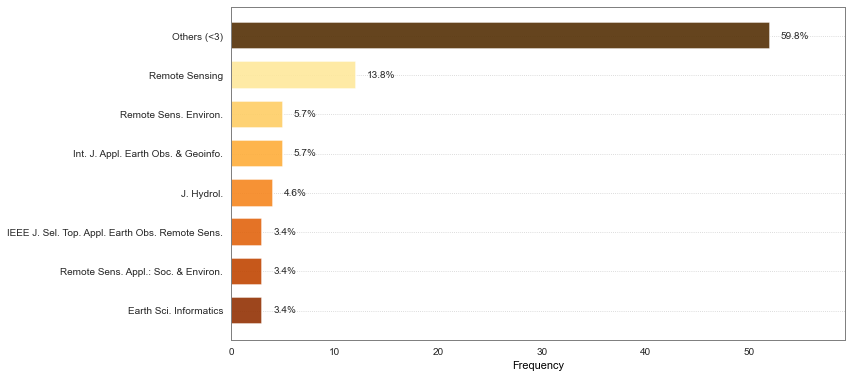

saved figures/Figure5.pdf


In [4]:
THRESHOLD = 3
ABBREVIATIONS = {
    "International Journal of Applied Earth Observation and Geoinformation": "Int. J. Appl. Earth Obs. & Geoinfo.",
    "Remote Sensing of Environment": "Remote Sens. Environ.",
    "Journal of Hydrology": "J. Hydrol.",
    "Earth Science Informatics": "Earth Sci. Informatics",
    "Remote Sensing Applications: Society and Environment": "Remote Sens. Appl.: Soc. & Environ.",
    "IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing":
        "IEEE J. Sel. Top. Appl. Earth Obs. Remote Sens.",
}
counts = biblio["Journal"].value_counts()
journals = counts[counts >= THRESHOLD].drop("IEEE Access", errors="ignore")
journals[f"Others (<{THRESHOLD})"] = counts[counts < THRESHOLD].sum()
journals = journals.rename(index=lambda j: ABBREVIATIONS.get(j, j))
display(journals.rename("Frequency").to_frame())

# Bottom-to-top: frequent journals in ascending order, "Others" on top
others = journals.index.str.startswith("Others")
plot = pd.concat([journals[~others].sort_values(kind="stable"), journals[others]])
colors = sns.color_palette("YlOrBr_r", len(plot))
colors[-1] = "#543005"  # darker tone for "Others"

with plt.rc_context(SMALL):
    fig, ax = plt.subplots(figsize=(11, 6))
    bars = ax.barh(plot.index, plot.values, color=colors, edgecolor="white", linewidth=1.5, height=0.7, alpha=0.9)
    ax.set_xlabel("Frequency", color=TXT)
    ax.grid(True, axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.4)
    pad = plot.max() * 0.02
    for bar, n in zip(bars, plot.values):
        ax.text(bar.get_width() + pad, bar.get_y() + bar.get_height() / 2, f"{n / plot.sum() * 100:.1f}%",
                va="center", ha="left", fontsize=10)
    ax.set_xlim(0, plot.max() * 1.12 + 1)
    gray_spines(ax)
    savefig(fig, 5)

## Figure 6 — Word cloud of the study titles
Colors follow the DL architecture families of Figures 9 and 10.

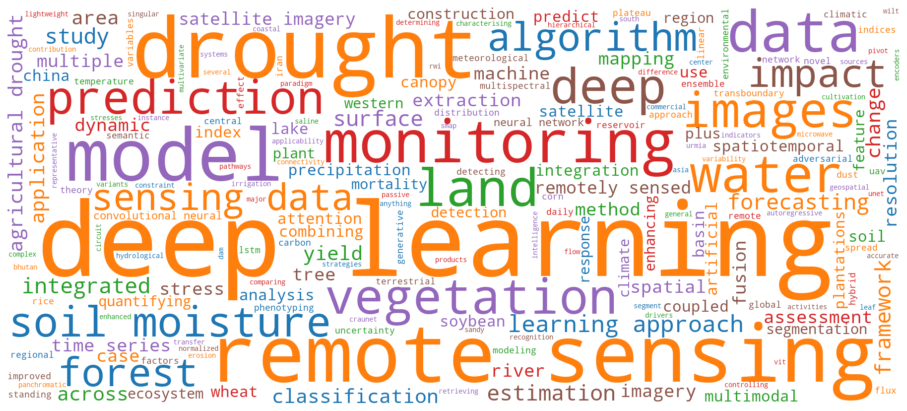

saved figures/Figure6.pdf


In [5]:
FAMILY_COLORS = {"CNN": "#FF7F0E", "RNN": "#1F77B4", "Transformer": "#2CA02C",
                 "DFNN": "#D62728", "Autoencoder": "#9467BD", "GAN": "#8C564B"}
STOPWORDS = {"in", "or", "and", "for", "from", "using", "new", "with", "the", "a", "by", "at", "to", "on",
             "based", "four", "mu", "tea", "us", "of", "an", "via"}

words = " ".join(biblio["Title"].dropna().astype(str)).split()
text = " ".join(w.lower() for w in words if w.lower() not in STOPWORDS and re.match("^[a-zA-Z]+$", w))
cloud = WordCloud(width=1800, height=800, background_color="white", colormap=ListedColormap(list(FAMILY_COLORS.values())),
                  min_font_size=10, max_words=200, random_state=42).generate(text)

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
savefig(fig, 6)

## Figure 7 — Study regions by country
Number of selected studies covering each country (a study covering several countries counts once for each of them).

Country
china                       29
united states of america    14
iran                         7
germany                      5
finland                      5
luxembourg                   5
italy                        4
france                       4
austria                      4
spain                        4


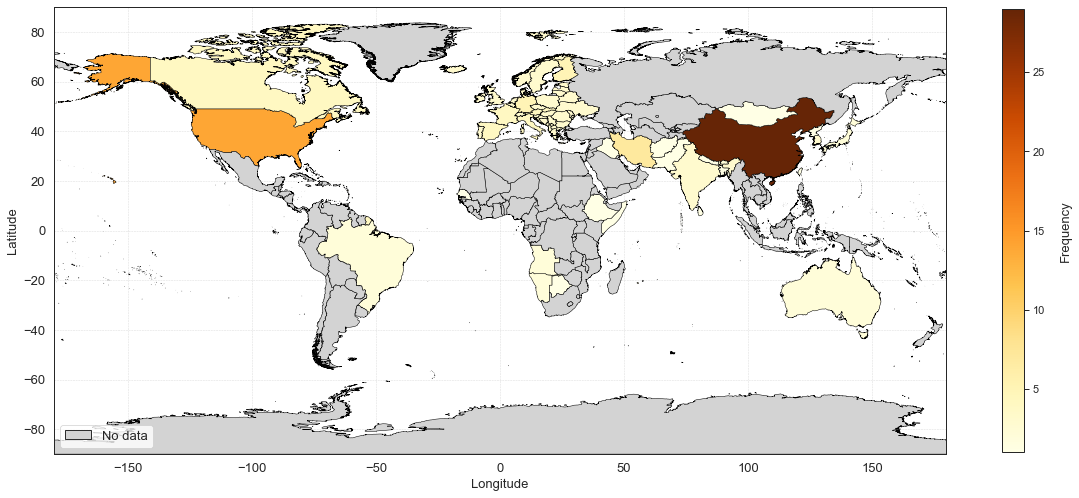

saved figures/Figure7.pdf


In [6]:
countries = explode(scope[["ID", "Country"]], "Country")
countries["Country"] = countries["Country"].str.lower().replace({"bosnia and herzegovina": "bosnia and herz."})
per_country = countries.drop_duplicates().groupby("Country").size().rename("Frequency")

world = gpd.read_file(SHAPEFILE)
world["key"] = world["NAME"].astype(str).str.strip().str.lower()
missing = set(per_country.index) - set(world["key"])
if missing:
    print("Countries not found in the shapefile:", missing)
world = world.merge(per_country, how="left", left_on="key", right_index=True)
print(per_country.sort_values(ascending=False).head(10).to_string())

with plt.rc_context(LARGE):
    fig, ax = plt.subplots(figsize=(20, 10))
    world.plot(ax=ax, column="Frequency", cmap="YlOrBr", edgecolor="black", linewidth=0.5, legend=True,
               legend_kwds={"orientation": "vertical", "shrink": 0.8, "aspect": 20},
               missing_kwds={"color": "lightgray"})
    cbar_ax = fig.axes[-1]
    cbar_ax.set_ylabel("Frequency", fontsize=13, labelpad=15)
    cbar_ax.tick_params(labelsize=11)
    ax.set_xlabel("Longitude", fontsize=13)
    ax.set_ylabel("Latitude", fontsize=13)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)
    ax.legend(handles=[Patch(facecolor="lightgray", edgecolor="black", label="No data")], loc="lower left", fontsize=13)
    savefig(fig, 7)

## Figure 8 — Drought types in the most studied countries
Number of studies per drought type in the five countries with the most studies.

Drought_Type,agricultural,hydrological,meteorological
China,14,4,11
Finland,3,0,2
Germany,3,0,2
Iran,2,2,3
United States,5,1,8


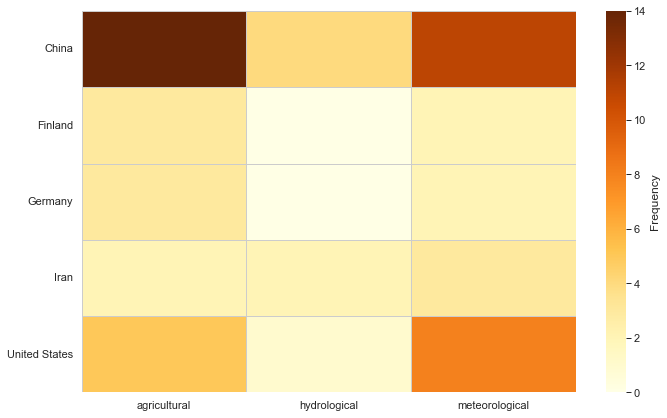

saved figures/Figure8.pdf


In [7]:
TOP_N = 5
dt = explode(scope[["ID", "Country", "Drought_Type"]], "Country")
dt["Country"] = dt["Country"].str.lower()
dt["Drought_Type"] = dt["Drought_Type"].astype(str).str.strip().str.lower()
top = dt["Country"].value_counts().head(TOP_N).index
table = pd.crosstab(dt.loc[dt["Country"].isin(top), "Country"], dt.loc[dt["Country"].isin(top), "Drought_Type"])
table = table.sort_index().sort_index(axis=1)
table.index = [{"united states of america": "United States"}.get(c, c.title()) for c in table.index]
display(table)

with plt.rc_context(SMALL):
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(table, linewidths=0.5, linecolor="#CCCCCC", cmap="YlOrBr", ax=ax,
                cbar_kws={"label": "Frequency"})
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelrotation=0, labelsize=11)
    ax.tick_params(axis="y", labelrotation=0, labelsize=11)
    ax.figure.axes[-1].yaxis.label.set_size(12)
    ax.figure.axes[-1].tick_params(labelsize=11)
    fig.tight_layout()
    savefig(fig, 8)

## Figure 9 — Temporal evolution of the DL architecture families
Number of studies per year using each architecture family, mapped from `DL_Architecture` and `DL_Model` (a study counts once per family).

Family,Transformer,GAN,CNN,DFNN,Autoencoder,RNN
Year,,,,,,
2019,0,0,0,1,0,0
2020,0,0,2,1,0,0
2021,0,1,2,3,1,1
2022,0,0,5,4,0,2
2023,1,0,8,2,0,10
2024,5,2,19,3,0,8
2025,4,1,15,5,0,11


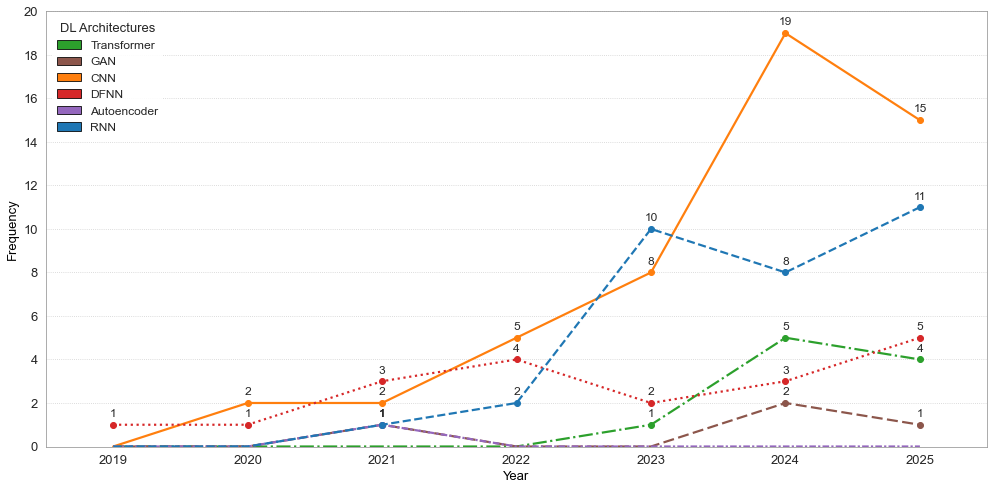

saved figures/Figure9.pdf


In [8]:
ARCH_MAP = {
    "CNN": "CNN", "1D CNN": "CNN", "1DCNN": "CNN", "3D-CNN": "CNN", "Conv2D": "CNN", "U-Net": "CNN", "UNet": "CNN",
    "EfficientUNet": "CNN", "ResUNet": "CNN", "ResUNet++": "CNN", "ResNet": "CNN", "VGG": "CNN", "FCN": "CNN",
    "DeepLabv3": "CNN", "DeepWaterMap": "CNN", "BCDU-Net": "CNN", "YOLO": "CNN", "SharpMask": "CNN",
    "EfficientNet": "CNN", "DenseNet": "CNN", "SegNet": "CNN", "AlexNet": "CNN", "GoogLeNet": "CNN",
    "Inception": "CNN", "MobileNet": "CNN",
    "RNN": "RNN", "LSTM": "RNN", "BiLSTM": "RNN", "Bi-LSTM": "RNN", "GRU": "RNN", "Bi-GRU": "RNN",
    "ConvLSTM": "RNN", "Seq2Seq": "RNN",
    "Transformer": "Transformer", "Informer": "Transformer", "TFT": "Transformer", "ViT": "Transformer",
    "SAM": "Transformer",
    "MLP": "DFNN", "DFNN": "DFNN", "MLF": "DFNN", "EEDNN": "DFNN",
    "AE": "Autoencoder", "DCAE": "Autoencoder", "VAE": "Autoencoder", "β-VAE": "Autoencoder",
    "CVAE": "Autoencoder", "VQ-VAE": "Autoencoder",
    "GAN": "GAN", "cGAN": "GAN",
}
FAMILY_ORDER = ["Transformer", "GAN", "CNN", "DFNN", "Autoencoder", "RNN"]
LINESTYLES = {"CNN": "-", "RNN": "--", "Transformer": "-.", "DFNN": ":",
              "Autoencoder": (0, (3, 1, 1, 1)), "GAN": (0, (5, 2))}


def family_of(token):
    """Architecture family of a DL_Architecture / DL_Model entry (None if unmapped)."""
    if "unet" in token.lower().replace("-", ""):
        return "CNN"
    if token in ARCH_MAP:
        return ARCH_MAP[token]
    return next((fam for key, fam in ARCH_MAP.items() if key.lower() in token.lower()), None)


fam = pd.concat([explode(models[["ID", c]], c).rename(columns={c: "token"}) for c in ("DL_Architecture", "DL_Model")])
fam["Family"] = fam["token"].map(family_of)
fam = fam.dropna(subset=["Family"])[["ID", "Family"]].drop_duplicates()
fam = fam.merge(biblio[["ID", "Year"]], on="ID").dropna(subset=["Year"]).astype({"Year": int})
pivot = fam.pivot_table(index="Year", columns="Family", aggfunc="size", fill_value=0)
pivot = pivot.reindex(range(pivot.index.min(), pivot.index.max() + 1), fill_value=0)
pivot = pivot.reindex(columns=FAMILY_ORDER, fill_value=0)
display(pivot)

with plt.rc_context(LARGE):
    fig, ax = plt.subplots(figsize=(14, 7))
    for f in FAMILY_ORDER:
        s = pivot[f]
        if (s > 0).any():
            ax.plot(pivot.index, s.values, linewidth=2.2, color=FAMILY_COLORS[f], linestyle=LINESTYLES[f], label=f)
            ax.plot(s.index[s > 0], s[s > 0].values, marker="o", markersize=6, linestyle="None", color=FAMILY_COLORS[f])
            for year, val in s[s > 0].items():
                ax.annotate(f"{val}", (year, val), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=12)
    ax.set_xlabel("Year", color=TXT)
    ax.set_ylabel("Frequency", color=TXT)
    ax.set_xticks(pivot.index)
    ax.set_xlim(pivot.index.min() - 0.5, pivot.index.max() + 0.5)
    ymax = int(pivot.values.max())
    ax.set_ylim(0, ymax + max(1, int(0.1 * ymax)))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, axis="y", linestyle=":", linewidth=0.8, color="gray", alpha=0.4)
    ax.set_axisbelow(True)
    ax.legend(handles=[Patch(facecolor=FAMILY_COLORS[f], edgecolor="black", label=f) for f in FAMILY_ORDER],
              loc="upper left", facecolor="white", framealpha=0.9, edgecolor="none",
              title="DL Architectures", title_fontsize=13)
    gray_spines(ax, "#999999", 0.8)
    fig.tight_layout()
    savefig(fig, 9)

## Figure 10 — Generic and specific DL models
Share of mentions of the generic architecture families (`DL_Architecture`) and of the ten most frequent specific models (`DL_Model`, excluding entries that only name a family). Percentages refer to the 183 plotted mentions.

Five specific models have two mentions each (Bi-GRU, EEDNN, EfficientUNet, SAM and YOLO) and compete for the last three positions; `SPECIFIC` keeps the selection of the published figure.

specific models with >= 2 mentions: {'LSTM': 19, 'U-Net': 17, 'MLP': 8, 'ConvLSTM': 5, 'GRU': 4, 'Bi-LSTM': 4, 'ResNet': 4, 'EfficientUNet': 2, 'EEDNN': 2, 'Bi-GRU': 2, 'YOLO': 2, 'SAM': 2}


,Share (%)
CNN,27.9
DFNN,10.4
GAN,2.2
RNN,17.5
Transformer,5.5
LSTM,10.4
U-Net,9.3
MLP,4.4
ConvLSTM,2.7
Bi-LSTM,2.2


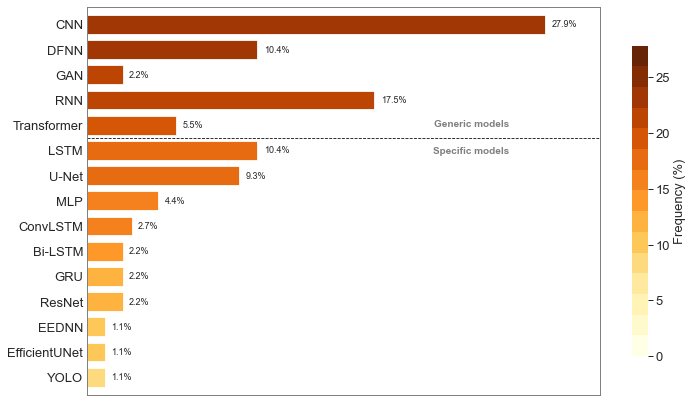

saved figures/Figure10.pdf


In [9]:
GENERIC = ["CNN", "DFNN", "GAN", "RNN", "Transformer"]
SPECIFIC = ["LSTM", "U-Net", "MLP", "ConvLSTM", "Bi-LSTM", "GRU", "ResNet", "EEDNN", "EfficientUNet", "YOLO"]

generic = explode(models[["ID", "DL_Architecture"]], "DL_Architecture")["DL_Architecture"].value_counts()[GENERIC]
specific = explode(models[["ID", "DL_Model"]], "DL_Model")["DL_Model"].value_counts()
print("specific models with >= 2 mentions:", specific[(specific >= 2) & ~specific.index.isin(GENERIC)].to_dict())
specific = specific[SPECIFIC]
pct = pd.concat([generic, specific]) / (generic.sum() + specific.sum()) * 100
display(pct.round(1).rename("Share (%)").to_frame())

cmap = ListedColormap(plt.get_cmap("YlOrBr")(np.linspace(0, 1, 15)))  # 15 discrete tones
colors = cmap(np.linspace(0.86, 0.30, len(pct)))                     # darker for the top bars

with plt.rc_context(LARGE):
    fig, ax = plt.subplots(figsize=(11.5, 7))
    y = np.arange(len(pct))[::-1]
    bars = ax.barh(y, pct.values, color=colors, edgecolor="white", height=0.75)
    ax.set_yticks(y, pct.index)
    for bar, v in zip(bars, pct.values):
        ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2, f"{v:.1f}%", va="center", fontsize=9)
    sep = y[len(GENERIC) - 1] - 0.5
    ax.axhline(sep, color="black", linestyle="--", linewidth=0.8)
    ax.text(0.75, sep + 0.35, "Generic models", transform=ax.get_yaxis_transform(), ha="center", va="bottom",
            fontsize=10, color="gray", fontweight="bold")
    ax.text(0.75, sep - 0.35, "Specific models", transform=ax.get_yaxis_transform(), ha="center", va="top",
            fontsize=10, color="gray", fontweight="bold")
    ax.set_xlim(0, pct.max() * 1.12)
    ax.set_ylim(-0.7, len(pct) - 0.3)
    ax.set_xticks([])
    ax.tick_params(axis="y", length=0)
    gray_spines(ax)
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=Normalize(0, pct.max()))
    cb = fig.colorbar(sm, ax=ax, shrink=0.8, aspect=20)
    cb.set_label("Frequency (%)")
    cb.outline.set_visible(False)
    savefig(fig, 10)

## Figure 11 — Remote sensing data sources
Share of mentions by source category (top-left panel) and, within each category, of its five most frequent sources. Sources mentioned at most twice are not shown; Aerial/UAV appears only in the category overview.

,Sensor,Frequency,Category
0,MODIS,32,Satellites/Sensors
1,Sentinel,21,Satellites/Sensors
2,Aerial/UAV,18,Aerial/UAV
3,Landsat,17,Satellites/Sensors
4,ERA5,8,Reanalyses/Models
5,CHIRPS,7,Precipitation Products
6,GLDAS,7,Reanalyses/Models
7,TRMM,7,Precipitation Products
8,SRTM,6,Satellites/Sensors
9,TerraClimate,4,Satellites/Sensors


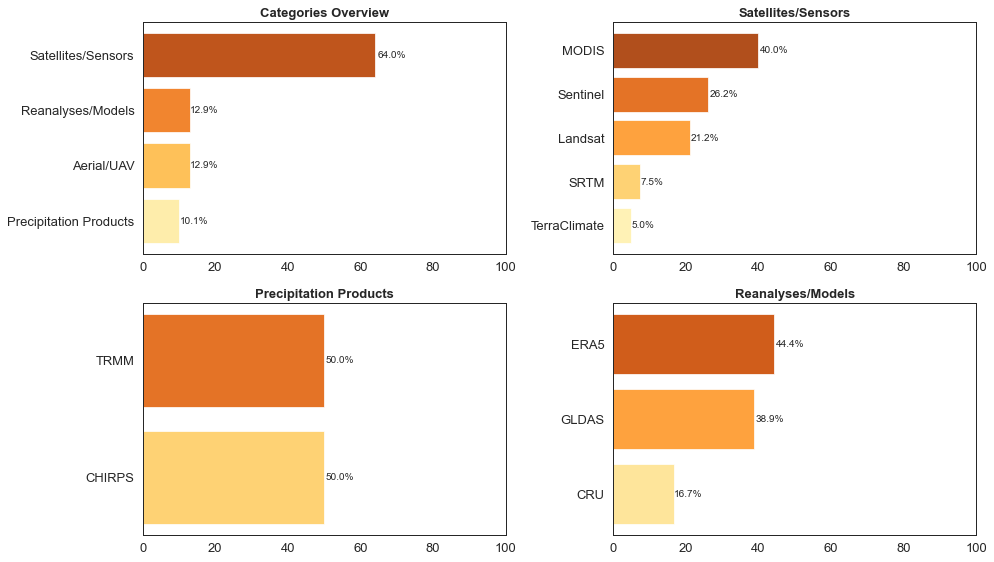

saved figures/Figure11.pdf


In [10]:
CANONICAL = {
    "landsat": "Landsat", "landsat 8": "Landsat", "landsat-8": "Landsat", "landsat tm": "Landsat",
    "landsat etm+": "Landsat", "oli": "Landsat", "tirs": "Landsat",
    "modis": "MODIS", "viirs": "VIIRS", "avhrr": "AVHRR (GIMMS)", "gimms": "AVHRR (GIMMS)", "gimms ndvi": "AVHRR (GIMMS)",
    "sentinel": "Sentinel", "sentinel-1": "Sentinel", "sentinel-2": "Sentinel", "msi": "Sentinel",
    "planetscope": "PlanetScope", "naip": "NAIP", "fy-4a": "FY-4A", "gf-2": "GaoFen-2", "gaofen": "GaoFen",
    "srtm": "SRTM", "aster": "ASTER-GDEM", "aster-gdem": "ASTER-GDEM", "sar": "SAR", "palsar": "PALSAR",
    "smap": "SMAP", "smos": "SMOS", "amsr2": "AMSR2", "grace": "GRACE",
    "trmm": "TRMM", "imerg": "IMERG", "cmorph": "CMORPH", "gsmap": "GSMaP", "persiann-cdr": "PERSIANN-CDR",
    "persiann": "PERSIANN", "chirps": "CHIRPS",
    "era5": "ERA5", "gldas": "GLDAS", "fldas": "FLDAS", "nldas": "NLDAS", "nldas-2": "NLDAS-2", "cldas": "CLDAS",
    "silo": "SILO", "noaa": "NOAA", "cru": "CRU", "esa cci": "ESA-CCI", "glass": "GLASS", "ealco": "EALCO",
    "cpc": "CPC", "esri": "ESRI", "etopo": "ETOPO", "etopo1": "ETOPO",
    "uav": "Aerial/UAV", "rgb camera": "Aerial/UAV", "camera": "Aerial/UAV", "lidar": "Aerial/UAV",
    "aerial camera": "Aerial/UAV", "hyperspectral": "Aerial/UAV", "aerial / uav": "Aerial/UAV",
}
CATEGORY_RULES = {
    "Satellites/Sensors": {"Landsat", "MODIS", "VIIRS", "AVHRR (GIMMS)", "Sentinel", "PlanetScope", "FY-4A", "GaoFen-2",
                           "GaoFen", "SRTM", "ASTER-GDEM", "SAR", "PALSAR", "SMAP", "SMOS", "AMSR2", "GRACE", "NAIP"},
    "Precipitation Products": {"TRMM", "IMERG", "CMORPH", "GSMaP", "PERSIANN-CDR", "PERSIANN", "CHIRPS"},
    "Reanalyses/Models": {"ERA5", "GLDAS", "FLDAS", "NLDAS", "NLDAS-2", "CLDAS", "SILO", "NOAA", "CRU", "ESA-CCI",
                          "GLASS", "EALCO", "CPC"},
    "DEM/Topography": {"ETOPO"},
    "Aerial/UAV": {"Aerial/UAV", "Camera"},
    "Other Datasets/Providers": {"ESRI"},
}
KEYWORDS = [("Reanalyses/Models", ["ERA", "GLDAS", "NLDAS", "FLDAS", "CCI", "CRU", "GLASS", "EALCO", "SILO", "CPC"]),
            ("Precipitation Products", ["TRMM", "IMERG", "CMORPH", "GSMAP", "PERSIANN", "CHIRPS"]),
            ("Aerial/UAV", ["UAV", "CAMERA", "LIDAR", "HYPERSPECTRAL", "AERIAL"]),
            ("DEM/Topography", ["ETOPO", "SRTM", "ASTER"]),
            ("Other Datasets/Providers", ["ESRI"])]


def category_of(source):
    for cat, items in CATEGORY_RULES.items():
        if source in items:
            return cat
    for cat, keys in KEYWORDS:
        if any(k in source.upper() for k in keys):
            return cat
    return "Satellites/Sensors"


sensors = explode(scope[["ID", "Sensor"]].assign(Sensor=scope["Sensor"].astype("string").str.replace("、", ";")), "Sensor")
sensors = sensors[~sensors["Sensor"].str.lower().isin({"n/i", "ni", "n.a.", "na"})]
counts = sensors["Sensor"].map(lambda s: CANONICAL.get(s.lower(), s)).value_counts()
src = counts[counts > 2].rename_axis("Sensor").reset_index(name="Frequency")
src["Category"] = src["Sensor"].map(category_of)
by_cat = src.groupby("Category")["Frequency"].sum().sort_values()
display(src)

TOP_N = 5
detail = src[src["Category"] != "Aerial/UAV"].copy()
detail["rank"] = detail.groupby("Category")["Frequency"].rank(method="first", ascending=False)
detail = detail[detail["rank"] <= TOP_N]
panels = ["Categories Overview", "Satellites/Sensors"] + sorted(set(detail["Category"]) - {"Satellites/Sensors"})


def pct_bars(ax, labels, values, title):
    p = values / values.sum() * 100
    bars = ax.barh(labels, p, color=sns.color_palette("YlOrBr", len(p)), edgecolor="white", alpha=0.9)
    for b, v in zip(bars, p):
        ax.text(b.get_width() * 1.01, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", ha="left", fontsize=10)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlim(0, 100)


with plt.rc_context(LARGE):
    nrows = int(np.ceil(len(panels) / 2))
    fig, axes = plt.subplots(nrows, 2, figsize=(14, 4 * nrows), squeeze=False)
    for ax, panel in zip(axes.flat, panels):
        if panel == "Categories Overview":
            pct_bars(ax, by_cat.index, by_cat.values, panel)
        else:
            sub = detail[detail["Category"] == panel].sort_values("Frequency")
            pct_bars(ax, sub["Sensor"], sub["Frequency"].values, panel)
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    fig.tight_layout()
    savefig(fig, 11)

## Figures 12 and 13 — Drought indices and task types per DL architecture
Share of the drought indices (Figure 12) and task types (Figure 13) among the studies of each architecture family. Indices with at most three mentions and architectures with at most three studies (task types) are not shown.

Drought_Index,PDSI,QuickDRI,SMI,SPEI,SPI,VCI
DL_Architecture,,,,,,
CNN,3,1,2,5,4,1
DFNN,1,1,0,4,1,1
GAN,0,0,2,1,0,0
RNN,3,1,2,7,5,1
Transformer,1,1,0,0,0,1


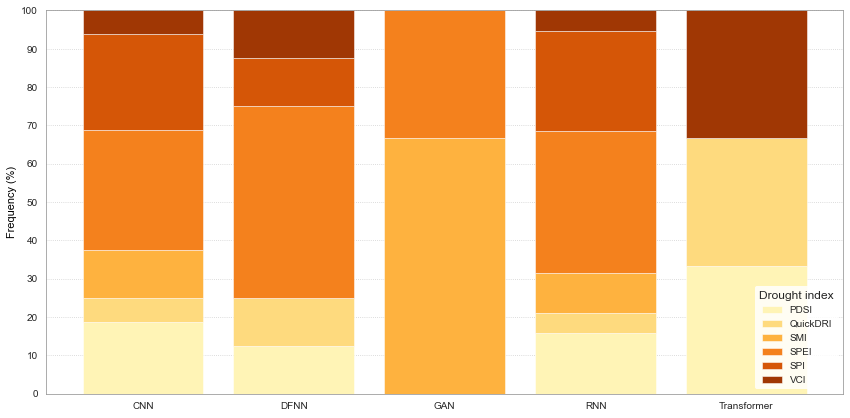

saved figures/Figure12.pdf


Task_Type,Classification,Data fusion,Object Detection,Regression,Segmentation
DL_Architecture,,,,,
CNN,13,1,2,19,16
DFNN,5,0,0,14,0
GAN,1,0,0,3,0
RNN,2,1,0,28,1
Transformer,3,0,0,5,2


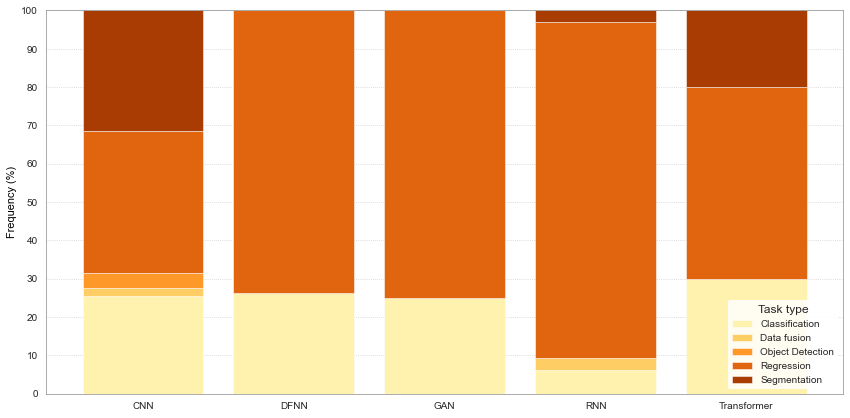

saved figures/Figure13.pdf


In [11]:
VALID_ARCH = ["CNN", "RNN", "Transformer", "DFNN", "GAN"]
MIN_COUNT = 3
arch = explode(models[["ID", "DL_Architecture"]], "DL_Architecture")
arch = arch[arch["DL_Architecture"].isin(VALID_ARCH)]


def stacked_pct(table, legend_title, number):
    """100% stacked bars of `table` (rows: architectures, columns: categories)."""
    pct = table.div(table.sum(axis=1), axis=0) * 100
    colors = sns.color_palette("YlOrBr", len(pct.columns))
    with plt.rc_context(SMALL):
        fig, ax = plt.subplots(figsize=(12, 6))
        x = np.arange(len(pct))
        bottom = np.zeros(len(pct))
        for color, col in zip(colors, pct.columns):
            ax.bar(x, pct[col].values, bottom=bottom, label=col, color=color, edgecolor="white", linewidth=0.5)
            bottom += pct[col].values
        ax.set_xticks(x, pct.index)
        ax.set_ylabel("Frequency (%)", color=TXT)
        ax.set_ylim(0, 100)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", linestyle=":", linewidth=0.8, alpha=0.4, color="gray")
        ax.set_axisbelow(True)
        ax.legend(title=legend_title, loc="lower right", facecolor="white", framealpha=0.85, edgecolor="none",
                  title_fontsize=12)
        gray_spines(ax, "#999999", 0.8)
        fig.tight_layout()
        savefig(fig, number)


# Figure 12: drought index
idx = explode(scope[["ID", "Drought_Index"]], "Drought_Index")
t12 = arch.merge(idx, on="ID").groupby(["DL_Architecture", "Drought_Index"]).size().unstack(fill_value=0)
t12 = t12.loc[:, t12.sum() > MIN_COUNT]
t12 = t12[t12.sum(axis=1) > 0]
display(t12)
stacked_pct(t12, "Drought index", 12)

# Figure 13: task type
task = explode(scope[["ID", "Task_Type"]], "Task_Type")
t13 = arch.merge(task, on="ID").groupby(["DL_Architecture", "Task_Type"]).size().unstack(fill_value=0)
t13 = t13[t13.sum(axis=1) > MIN_COUNT]
display(t13)
stacked_pct(t13, "Task type", 13)

## Figure 14 — Lead times
Minimum and maximum lead times (days) reported by the forecasting studies, colored and sized by temporal resolution.

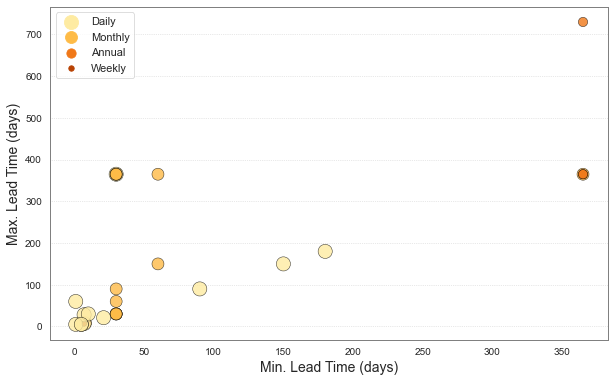

saved figures/Figure14.pdf


In [12]:
lt = lead.rename(columns=lambda c: c.strip().lower()).dropna(subset=["lt_min", "lt_max", "tr"])

with plt.rc_context(SMALL):
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.scatterplot(x="lt_min", y="lt_max", hue="tr", size="tr", sizes=(30, 200), palette="YlOrBr", data=lt,
                    alpha=0.8, edgecolor="k", linewidth=0.5, ax=ax)
    ax.yaxis.grid(True, linestyle=":", linewidth=0.7, color="lightgray")
    ax.xaxis.grid(False)
    ax.set_xlabel("Min. Lead Time (days)", fontsize=14)
    ax.set_ylabel("Max. Lead Time (days)", fontsize=14)
    ax.legend(title_fontsize=12, fontsize=11, loc="best", frameon=True)
    gray_spines(ax)
    savefig(fig, 14)